Questo notebook contiene le sessioni di training dell'agente DDQN_PPR con funzione train_with_ppr in ambienti con p_err tipo X (bitflip) crescente. Rispettivamente:
- p_err 0.003 [0.001] ----------------------- | run : 17/10 042142 | best_avg_500_train : 1663
- p_err 0.005 [0.001, 0.003] ---------------- | run : 17/10 000003 | best_avg_500_train : 551
- p_err 0.007 [0.001, 0.003, 0.005] --------- | run : 18/10 213903 | best_avg_500_train : 268
- p_err 0.009 [0.001, 0.003, 0.005, 0.007] -- | run : 19/10 025723 | best_avg_500_train : 159


Tutte le sessioni di training sono state svolte con una politica di eps-annealing lineare con eps 1 --> 0.02 in 75k steps

Tutte le sessioni di training sono state svolte con una politica di psi-annealing lineare con psi 0.85 --> 0.02 in 175k steps;

Tutte le sessioni sono state svolte con un tau_increment di 0.0001

Per ogni sessione sono presenti addestramento, una prima valutazione grafica di parametri e metriche di addestramento e il test effettuato sulla politica ottenuta.

In [10]:
# import delle librerie completo
import numpy as np
import matplotlib.pyplot as plt
import torch


from Function_Library import *
from Environments import *
from Agent_Torch import *

import json
import copy
import os
import time
import gc

## p=0.003 [0.001] 

In [11]:
# env 0.003 con una libreria basata su [0.001]

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.003,            
                    "p_meas": 0.003,            
                    "success_threshold": 1500,   # imposto circa la vita media ottenuta by scratch con p 0.003
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,  
                    "max_eps": 1.0,
                    "final_eps": 0.02,      
                    "exploration_fraction": 75000,
                    "max_psi": 0.85,             
                    "final_psi": 0.02,
                    "ppr_fraction": 175000,                       
                    "target_network_update_freq":5000, 
                    "gamma": 0.99}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [13]:
# 1 - decoder statico 
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali 
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# inizializzo l'Optimizer 
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [15]:
# libreria di policy per PPR
model_paths = [r'runs/DDQN_d5_p0.001_20251013-230503/checkpoints/best_policy_net.pth'
               ]
library = make_library(model_paths, policy_net, device)
print(f'Library creata con {len(library)} modelli.')

Library creata con 1 modelli.


In [ ]:
# train eseguito train_wit_ppr
timeS = time.time()
train_with_ppr(agent, env, policy, policy_net, memory, library, all_configs, device=device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento con PPR su 1000000 passi. Log in: runs/DDQN_PPR_d5_p0.003_20260205-142215

---------------------------------
Step : 5958/1000000
Episode : 100
Policy Index k : 1
Episode Step : 118 with 90 "reuse" actions
Episode Reward : 80.0
Avg Reward (Last 500 Ep) : 38.51
Best Avg Reward : -inf
Episode Lifetime : 510
Avg Lifetime (Last 500 Ep) : 262.55
Best Avg Lifetime : -inf
Success threshold : 1500
Patience Counter : 0/1000
Metrics : Loss: 0.0476, Epsilon: 0.9221, Psi: 0.8217
Total Training Time : 50.57s
---------------------------------
                              

---------------------------------
Step : 13071/1000000
Episode : 200
Policy Index k : 1
Episode Step : 38 with 32 "reuse" actions
Episode Reward : 32.0
Avg Reward (Last 500 Ep) : 42.25
Best Avg Reward : -inf
Episode Lifetime : 175
Avg Lifetime (Last 500 Ep) : 288.00
Best Avg Lifetime : -inf
Success threshold : 1500
Patience Counter : 0/1000
Metrics : Loss: 0.0908, Epsilon: 0.8292, Psi: 0.7880
Total Training Ti

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

3 ore e 54 min


### valutazione training log

In [ ]:
# estrazione log di allenamento 
TRAINING_LOG_PATH =  r'runs\DDQN_PPR_d5_p0.003_20251017-042142\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con train_with_ppr : 
step = np.array([log_data['step'] for log_data in training_history])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reused_action = np.array([log_data['reuse_actions'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
psi = np.array([log_data['psi'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]

print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_PPR_d5_p0.003_20251017-042142\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 4111
numero step totali : 999976
best avg lifetime (rolling lenght 500) : 1663.36
----------------------------------------------------------


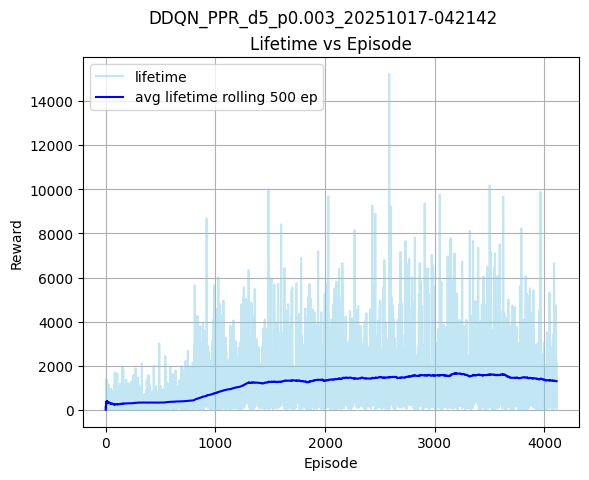

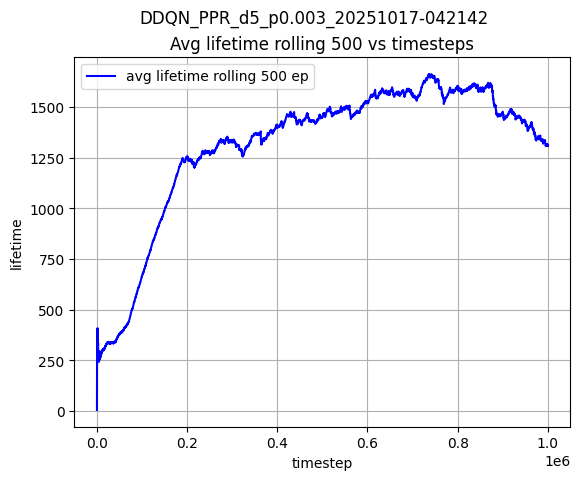

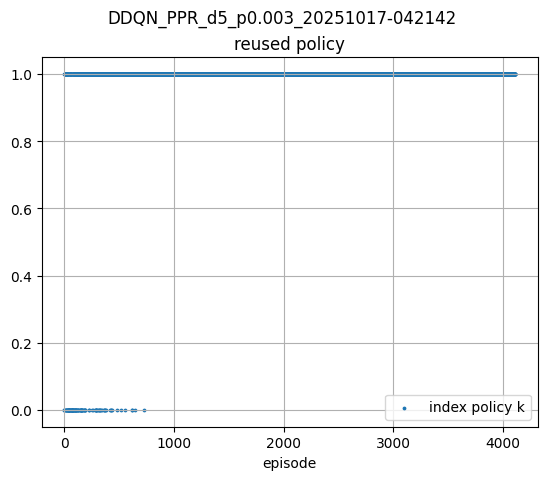

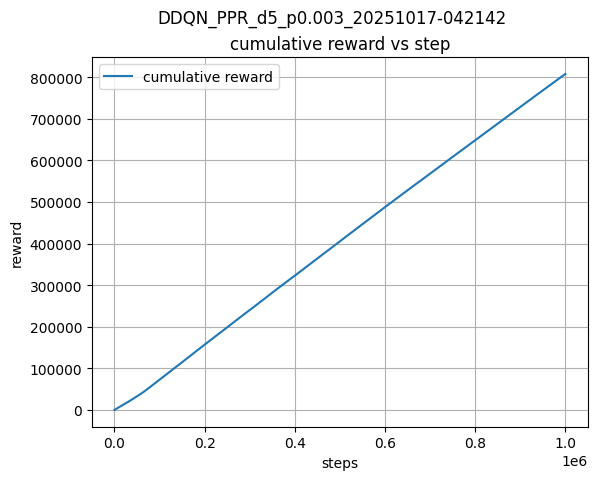

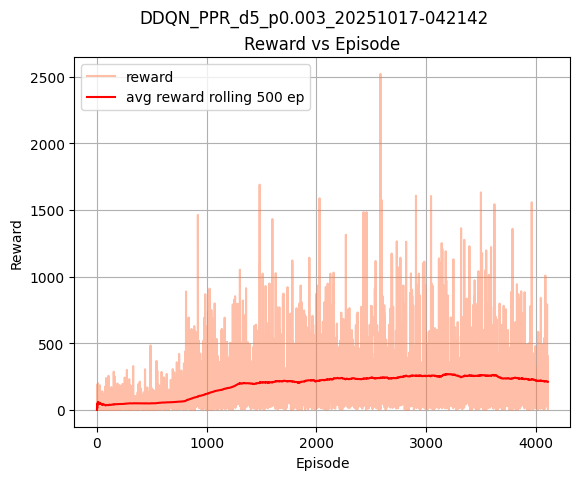

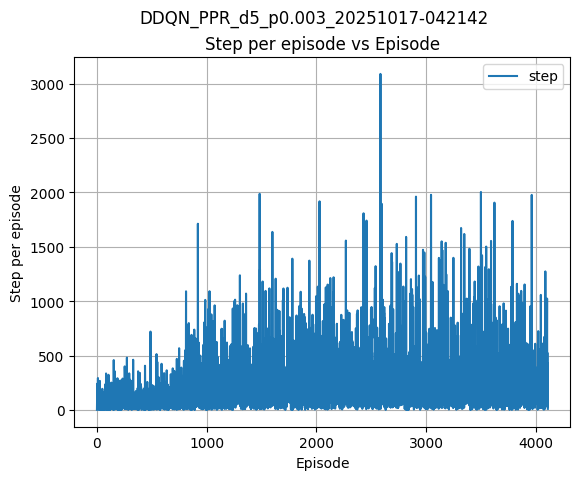

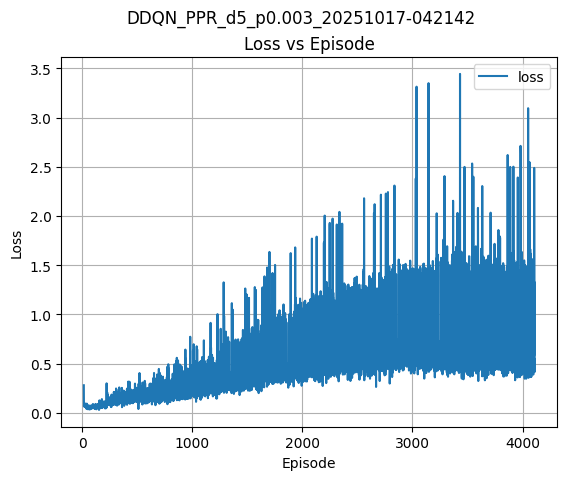

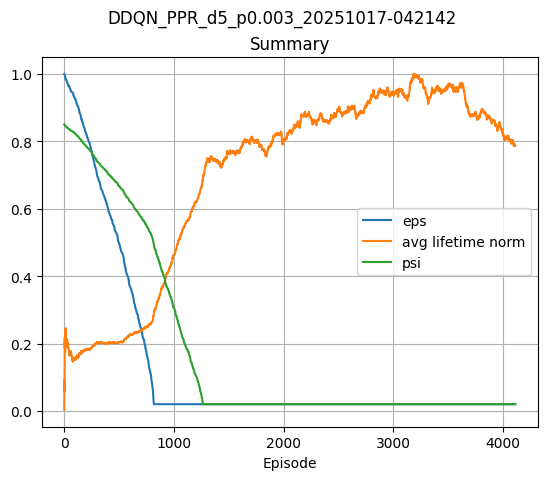

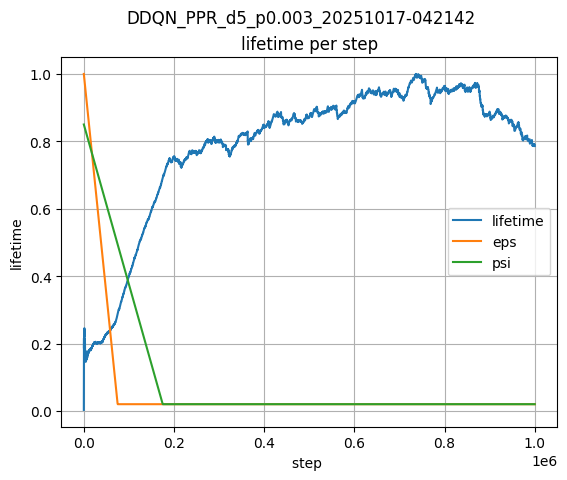

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# add
# k vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.scatter(episode, index_k, s=3, label='index policy k')
ax.set_title('reused policy')
ax.set_xlabel('episode')
ax.set_ylabel('')
ax.legend()
ax.grid()
plt.show()

# add 
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, np.cumsum(reward), label='cumulative reward')
ax.set_title('cumulative reward vs step')
ax.set_xlabel('steps')
ax.set_ylabel('reward')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
ax.plot(episode, psi, label='psi')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

# add
# avg lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime/np.max(avg_lifetime), label='lifetime')
ax.plot(step, eps, label = 'eps')
ax.plot(step, psi, label='psi')
ax.set_title('lifetime per step')
ax.set_xlabel('step ')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()



### test della policy ottenuta

In [ ]:
BEST_MODEL_PATH = r'runs\DDQN_PPR_d5_p0.003_20251017-042142\checkpoints\best_policy_net.pth'
policy_net.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
policy_net.eval() 

run = BEST_MODEL_PATH.split('\\')[1]

# test
N_episode = 1500
test_path = test_agent_performance(env, policy_net, policy, N_episode, device, log=True, run_name=run)



--- Inizio Test Deterministico (Episodi: 1500) ---
tested episode : 10, steps : 211, reward : 183.0, lifetime : 1050
tested episode : 20, steps : 340, reward : 307.0, lifetime : 1765
tested episode : 30, steps : 485, reward : 425.0, lifetime : 2630
tested episode : 40, steps : 5, reward : 2.0, lifetime : 45
tested episode : 50, steps : 796, reward : 710.0, lifetime : 4180
tested episode : 60, steps : 331, reward : 276.0, lifetime : 1720
tested episode : 70, steps : 72, reward : 62.0, lifetime : 360
tested episode : 80, steps : 516, reward : 445.0, lifetime : 2875
tested episode : 90, steps : 837, reward : 734.0, lifetime : 4395
tested episode : 100, steps : 481, reward : 436.0, lifetime : 2645
tested episode : 110, steps : 810, reward : 732.0, lifetime : 4290
tested episode : 120, steps : 60, reward : 48.0, lifetime : 345
tested episode : 130, steps : 390, reward : 343.0, lifetime : 2190
tested episode : 140, steps : 246, reward : 224.0, lifetime : 1380
tested episode : 150, steps : 1

In [4]:
test_path = r'test_runs\test_policy_DDQN_PPR_d5_p0.003_20251017-042142.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.mean(test_lifetimes)

Contenuto di test_runs\test_policy_DDQN_PPR_d5_p0.003_20251017-042142.json estratto con successo:


In [5]:
# nb: il paper originale calcola la vita media su un test greedy eseguito su un numero di episodi tale da garantire che
#     l'agente veda "almeno 1000000 di faulty syndrome" 
# la lifetime è calcolata come il  numero di singoli strati di ft syndrome creati in un qubit logico
# --> questo dato corrisponde alla somma di tutte le lifetime degli episodi di un test
print(np.sum(test_lifetimes))
# 1500 ep, 19 min
N_episode = 1500

3099740


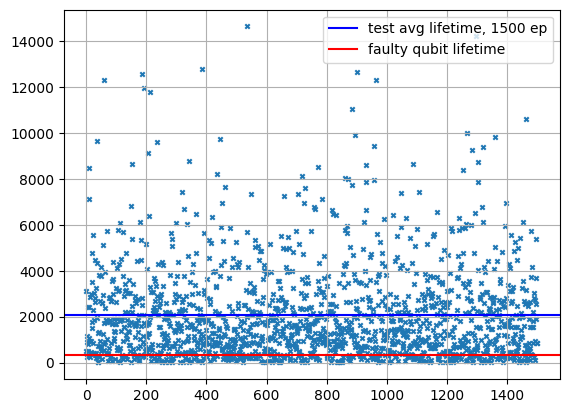

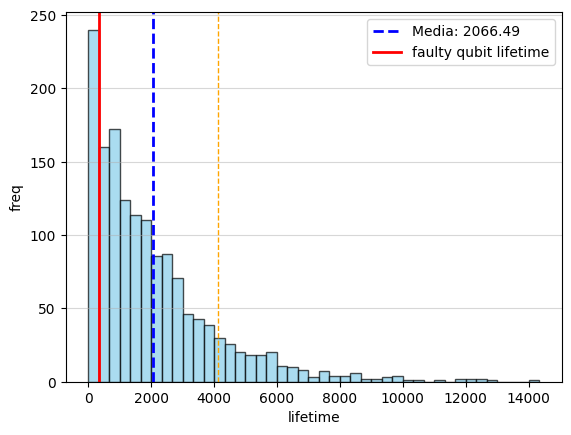

In [6]:
faulty_qubit_lifetime = 1/all_configs['p_phys']

fig, ax = plt.subplots()
ax.axhline(test_avg_lifetime, c='b', label=f'test avg lifetime, {N_episode} ep')
ax.scatter(range(N_episode), test_lifetimes, marker='x', s=10 )
ax.axhline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r')
ax.grid()
ax.legend()
plt.show()

bins = np.arange(0, np.max(test_lifetimes), faulty_qubit_lifetime)
# istogramma

plt.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.7, color='skyblue')
# Aggiungi linee di riferimento per la Media e la Deviazione Standard
plt.axvline(test_avg_lifetime, c='b', ls='dashed', linewidth=2, label=f'Media: {test_avg_lifetime:.2f}')
plt.axvline(test_avg_lifetime + test_std_lifetime, color='orange', linestyle='dashed', linewidth=1)
if test_avg_lifetime - test_std_lifetime > 0: plt.axvline(test_avg_lifetime - test_std_lifetime, color='orange', linestyle='dashed', linewidth=1, label=f'Media ± Std: {test_std_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r', lw=2)
# Etichette e Titolo
plt.xlabel('lifetime')
plt.ylabel('freq')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()



## p=0.005 [0.003, 0.001]

In [7]:
# env 0.005 con una libreria basata su [0.001, 0.003]

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.005,            
                    "p_meas": 0.005,            
                    "success_threshold": 555,   # imposto circa la vita media ottenuta by scratch con p 0.005
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,  
                    "max_eps": 1.0,
                    "final_eps": 0.02,      
                    "exploration_fraction": 75000,
                    "max_psi": 0.85,              
                    "final_psi": 0.02,
                    "ppr_fraction": 175000,                       
                    "target_network_update_freq":5000, 
                    "gamma": 0.99}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali 
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# inizializzo l'Optimizer 
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# libreria di policy per PPR
model_paths = [r'runs\DDQN_d5_p0.001_20251013-230503\checkpoints\best_policy_net.pth',
               r'runs\DDQN_d5_p0.003_20251014-034106\checkpoints\best_policy_net.pth'
               ]
library = make_library(model_paths, policy_net, device)
print(f'Library creata con {len(library)} modelli.')

Library creata con 2 modelli.


In [ ]:
# train eseguito train_wit_ppr
timeS = time.time()
train_with_ppr(agent, env, policy, policy_net, memory, library, all_configs, device=device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento con PPR su 1000000 passi. Log in: runs\DDQN_PPR_d5_p0.005_20251017-000003

---------------------------------
Step : 3618/1000000
Episode : 100
Policy Index k : 1
Episode Step : 50 with 40 "reuse" actions
Episode Reward : 31.0
Avg Reward (Last 500 Ep) : 20.28
Best Avg Reward : -inf
Episode Lifetime : 185
Avg Lifetime (Last 500 Ep) : 111.95
Best Avg Lifetime : -inf
Success threshold : 555
Patience Counter : 0/1000
Metrics : Loss: 0.0634, Epsilon: 0.9527, Psi: 0.8328
Total Training Time : 41.04s
---------------------------------
                              

---------------------------------
Step : 8372/1000000
Episode : 200
Policy Index k : 2
Episode Step : 103 with 80 "reuse" actions
Episode Reward : 72.0
Avg Reward (Last 500 Ep) : 24.08
Best Avg Reward : -inf
Episode Lifetime : 330
Avg Lifetime (Last 500 Ep) : 129.30
Best Avg Lifetime : -inf
Success threshold : 555
Patience Counter : 0/1000
Metrics : Loss: 0.0611, Epsilon: 0.8906, Psi: 0.8103
Total Training Time 

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

4 ore e 21 min


### valutazione training log

In [ ]:
# estrazione log di allenamento 
TRAINING_LOG_PATH =  r'runs\DDQN_PPR_d5_p0.005_20251017-000003\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con train_with_ppr : 
step = np.array([log_data['step'] for log_data in training_history])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reused_action = np.array([log_data['reuse_actions'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
psi = np.array([log_data['psi'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]

print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_PPR_d5_p0.005_20251017-000003\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 8023
numero step totali : 999989
best avg lifetime (rolling lenght 500) : 551.28
----------------------------------------------------------


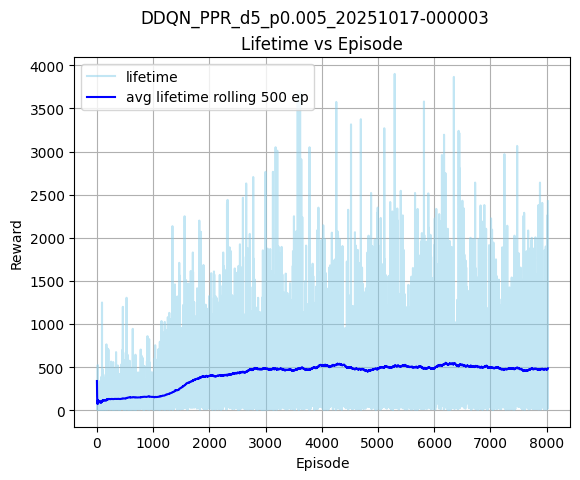

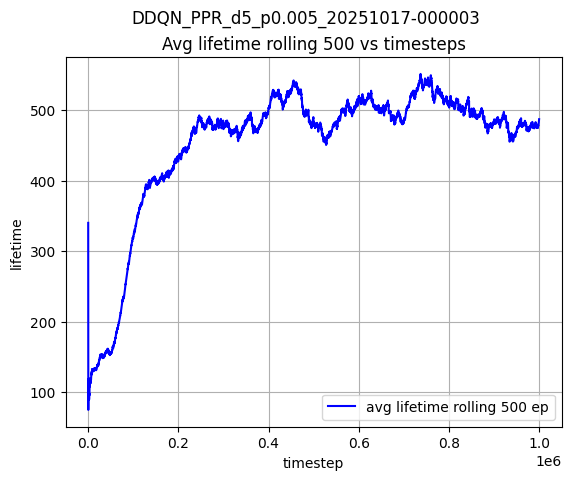

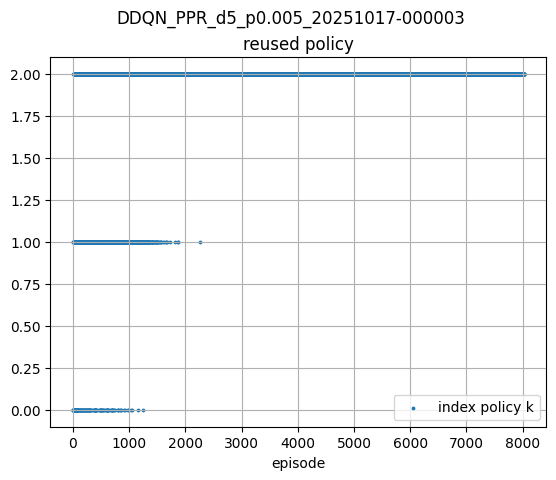

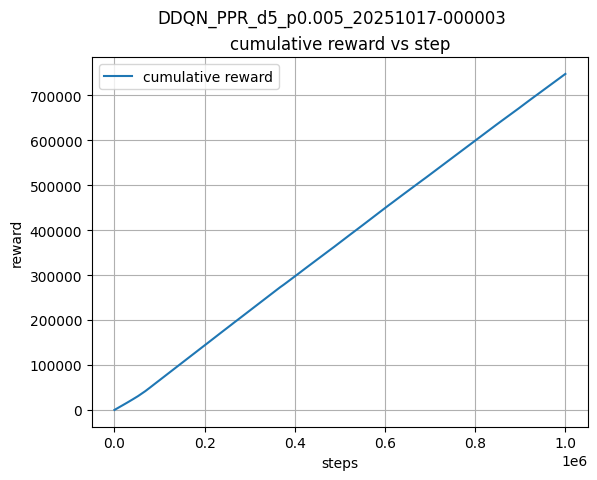

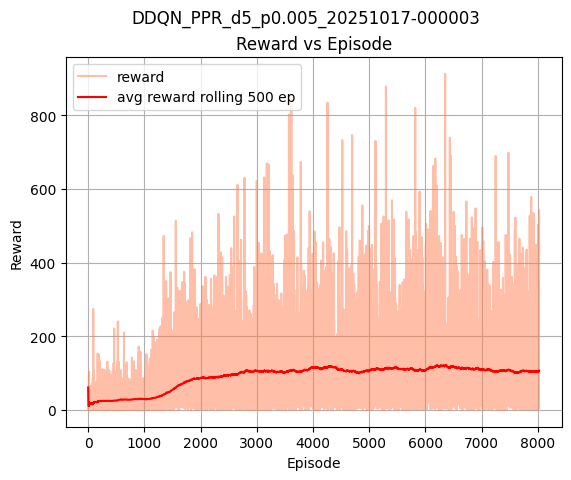

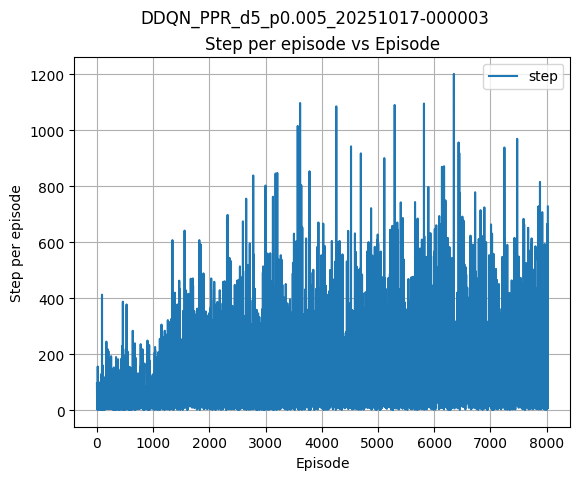

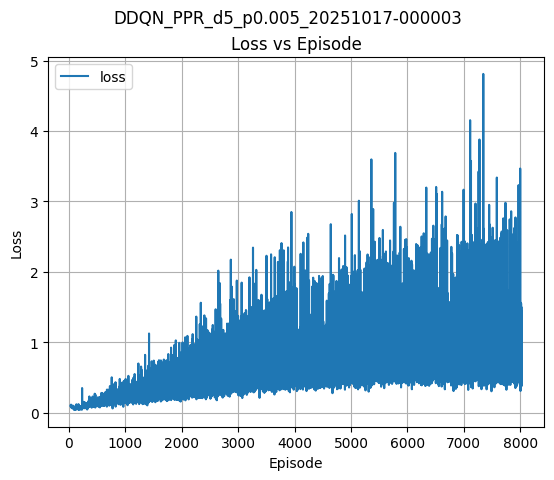

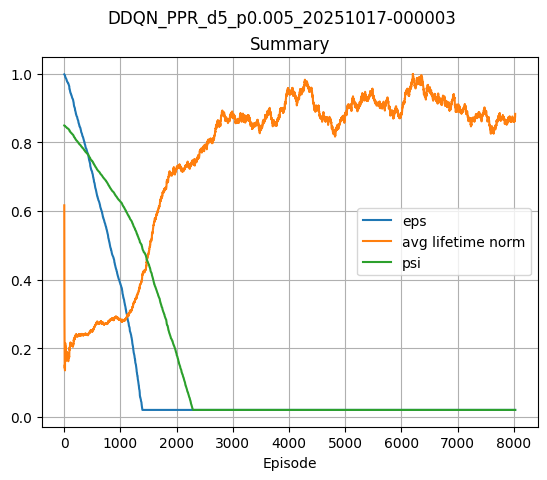

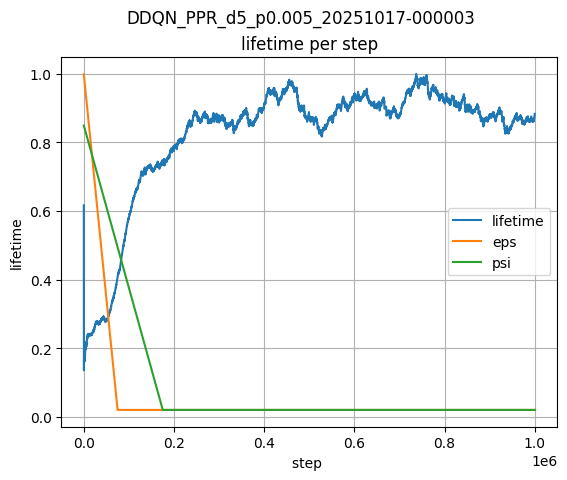

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# add
# k vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.scatter(episode, index_k, s=3, label='index policy k')
ax.set_title('reused policy')
ax.set_xlabel('episode')
ax.set_ylabel('')
ax.legend()
ax.grid()
plt.show()

# add 
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, np.cumsum(reward), label='cumulative reward')
ax.set_title('cumulative reward vs step')
ax.set_xlabel('steps')
ax.set_ylabel('reward')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
ax.plot(episode, psi, label='psi')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

# add
# avg lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime/np.max(avg_lifetime), label='lifetime')
ax.plot(step, eps, label = 'eps')
ax.plot(step, psi, label='psi')
ax.set_title('lifetime per step')
ax.set_xlabel('step ')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()



### test della policy ottenuta

In [ ]:
BEST_MODEL_PATH = r'runs\DDQN_PPR_d5_p0.005_20251017-000003\checkpoints\best_policy_net.pth'
policy_net.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
policy_net.eval() 

run = BEST_MODEL_PATH.split('\\')[1]

# test
N_episode = 3500
test_path = test_agent_performance(env, policy_net, policy, N_episode, device, log=True, run_name=run)



--- Inizio Test Deterministico (Episodi: 3500) ---
tested episode : 10, steps : 107, reward : 91.0, lifetime : 370
tested episode : 20, steps : 310, reward : 265.0, lifetime : 1160
tested episode : 30, steps : 17, reward : 16.0, lifetime : 95
tested episode : 40, steps : 67, reward : 49.0, lifetime : 210
tested episode : 50, steps : 298, reward : 254.0, lifetime : 1090
tested episode : 60, steps : 157, reward : 127.0, lifetime : 640
tested episode : 70, steps : 81, reward : 69.0, lifetime : 300
tested episode : 80, steps : 415, reward : 355.0, lifetime : 1485
tested episode : 90, steps : 41, reward : 32.0, lifetime : 135
tested episode : 100, steps : 10, reward : 8.0, lifetime : 60
tested episode : 110, steps : 523, reward : 435.0, lifetime : 1940
tested episode : 120, steps : 198, reward : 167.0, lifetime : 710
tested episode : 130, steps : 153, reward : 140.0, lifetime : 615
tested episode : 140, steps : 210, reward : 171.0, lifetime : 815
tested episode : 150, steps : 264, reward :

In [8]:
test_path = r'test_runs\test_policy_DDQN_PPR_d5_p0.005_20251017-000003.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.mean(test_lifetimes)

Contenuto di test_runs\test_policy_DDQN_PPR_d5_p0.005_20251017-000003.json estratto con successo:


In [9]:
# nb: il paper originale calcola la vita media su un test greedy eseguito su un numero di episodi tale da garantire che
#     l'agente veda "almeno 1000000 di faulty syndrome" 
# la lifetime è calcolata come il  numero di singoli strati di ft syndrome creati in un qubit logico
# --> questo dato corrisponde alla somma di tutte le lifetime degli episodi di un test
print(np.sum(test_lifetimes))
# 3500 ep, 19 min
N_episode = 3500

2139815


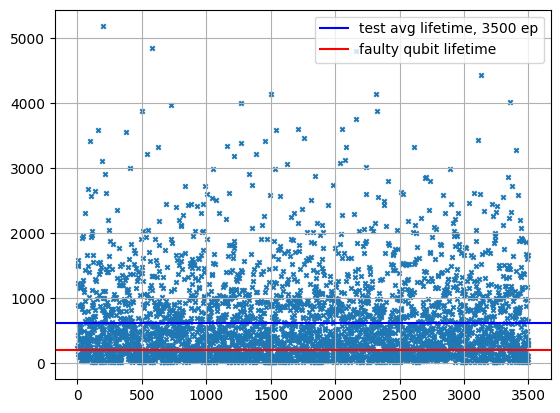

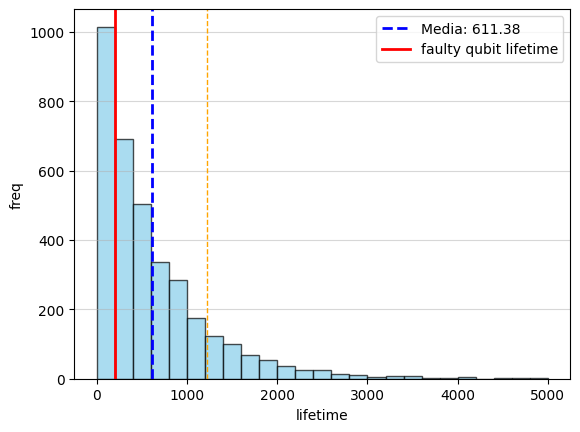

In [10]:
faulty_qubit_lifetime = 1/all_configs['p_phys']

fig, ax = plt.subplots()
ax.axhline(test_avg_lifetime, c='b', label=f'test avg lifetime, {N_episode} ep')
ax.scatter(range(N_episode), test_lifetimes, marker='x', s=10 )
ax.axhline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r')
ax.grid()
ax.legend()
plt.show()

bins = np.arange(0, np.max(test_lifetimes), faulty_qubit_lifetime)
# istogramma

plt.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.7, color='skyblue')
# Aggiungi linee di riferimento per la Media e la Deviazione Standard
plt.axvline(test_avg_lifetime, c='b', ls='dashed', linewidth=2, label=f'Media: {test_avg_lifetime:.2f}')
plt.axvline(test_avg_lifetime + test_std_lifetime, color='orange', linestyle='dashed', linewidth=1)
if test_avg_lifetime - test_std_lifetime > 0: plt.axvline(test_avg_lifetime - test_std_lifetime, color='orange', linestyle='dashed', linewidth=1, label=f'Media ± Std: {test_std_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r', lw=2)
# Etichette e Titolo
plt.xlabel('lifetime')
plt.ylabel('freq')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()



## p=0.007 [0.005, 0.003, 0.001] 

In [11]:
# env 0.007 con una libreria basata su [0.001, 0.003, 0.005]

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.007,            
                    "p_meas": 0.007,            
                    "success_threshold": 290,   # imposto circa la vita media ottenuta by scratch con p 0.007
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,  
                    "max_eps": 1.0,
                    "final_eps": 0.02,      
                    "exploration_fraction": 75000,
                    "max_psi": 0.85,             
                    "final_psi": 0.02,
                    "ppr_fraction": 175000,                       
                    "target_network_update_freq":5000, 
                    "gamma": 0.99}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali 
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# inizializzo l'Optimizer 
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN 
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# libreria di policy per PPR
model_paths = [r'runs\DDQN_d5_p0.001_20251013-230503\checkpoints\best_policy_net.pth',
               r'runs\DDQN_d5_p0.003_20251014-034106\checkpoints\best_policy_net.pth',
               r'runs\DDQN_d5_p0.005_20251014-081237\checkpoints\best_policy_net.pth'
               ]
library = make_library(model_paths, policy_net, device)
print(f'Library creata con {len(library)} modelli.')

Library creata con 3 modelli.


In [ ]:
# train eseguito train_wit_ppr
timeS = time.time()
train_with_ppr(agent, env, policy, policy_net, memory, library, all_configs, device=device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento con PPR su 1000000 passi. Log in: runs\DDQN_PPR_d5_p0.007_20251018-213903

---------------------------------
Step : 3049/1000000
Episode : 100
Policy Index k : 1
Episode Step : 36 with 29 "reuse" actions
Episode Reward : 21.0
Avg Reward (Last 500 Ep) : 16.56
Best Avg Reward : -inf
Episode Lifetime : 90
Avg Lifetime (Last 500 Ep) : 81.20
Best Avg Lifetime : -inf
Success threshold : 290
Patience Counter : 0/1000
Metrics : Loss: 0.0536, Epsilon: 0.9602, Psi: 0.8355
Total Training Time : 41.18s
---------------------------------
                              

---------------------------------
Step : 6623/1000000
Episode : 200
Policy Index k : 1
Episode Step : 28 with 21 "reuse" actions
Episode Reward : 16.0
Avg Reward (Last 500 Ep) : 17.47
Best Avg Reward : -inf
Episode Lifetime : 60
Avg Lifetime (Last 500 Ep) : 86.30
Best Avg Lifetime : -inf
Success threshold : 290
Patience Counter : 0/1000
Metrics : Loss: 0.0792, Epsilon: 0.9135, Psi: 0.8186
Total Training Time : 96.

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

5 ore e 18 min


### valutazione training log

In [ ]:
# estrazione log di allenamento 
TRAINING_LOG_PATH =  r'runs\DDQN_PPR_d5_p0.007_20251018-213903\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con train_with_ppr : 
step = np.array([log_data['step'] for log_data in training_history])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reused_action = np.array([log_data['reuse_actions'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
psi = np.array([log_data['psi'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]

print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_PPR_d5_p0.007_20251018-213903\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 12769
numero step totali : 999933
best avg lifetime (rolling lenght 500) : 268.49
----------------------------------------------------------


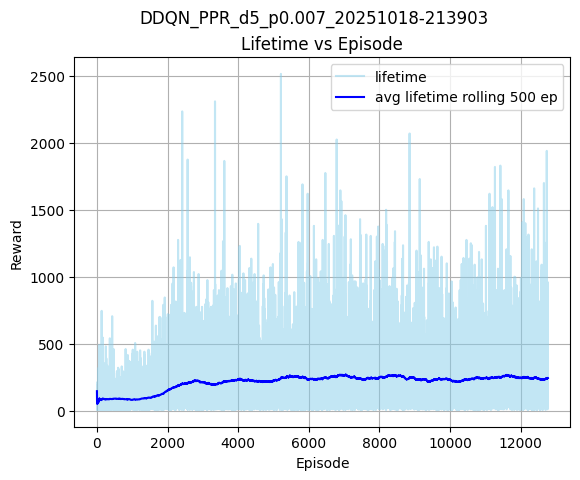

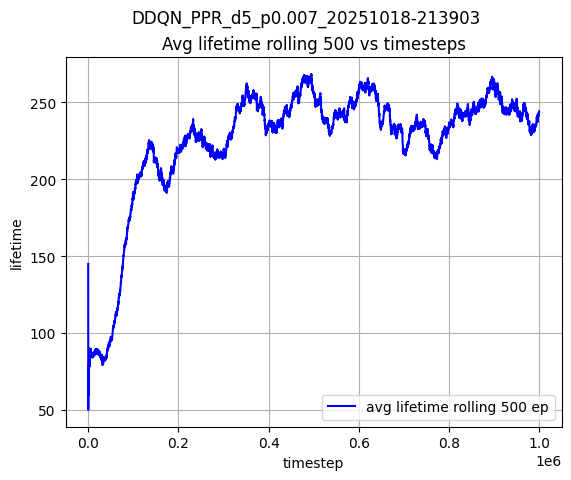

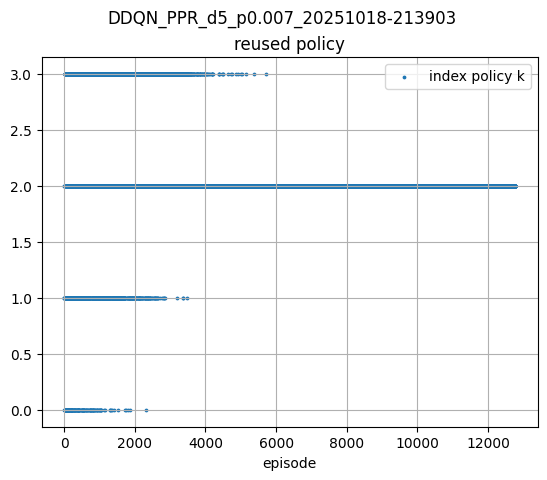

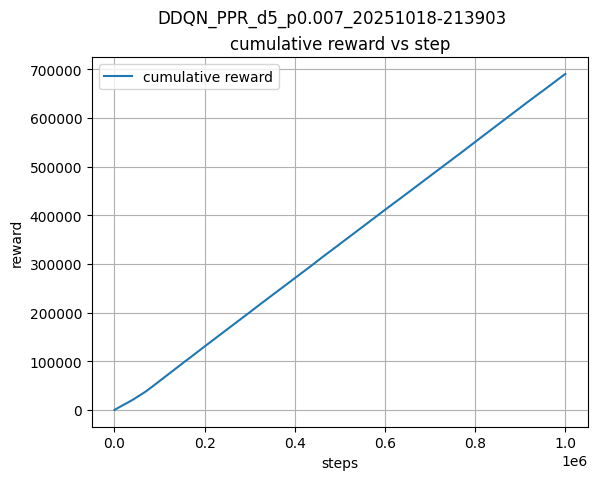

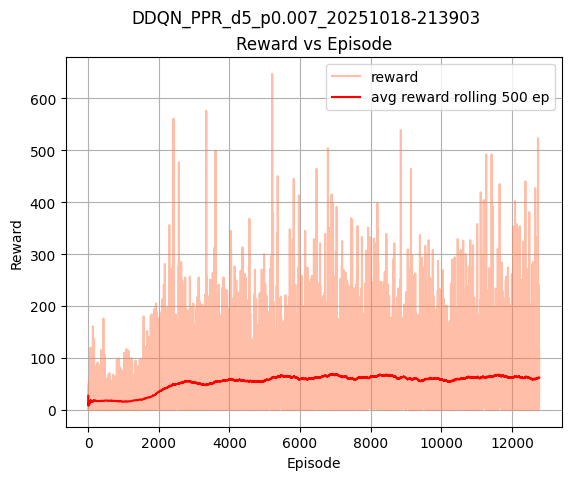

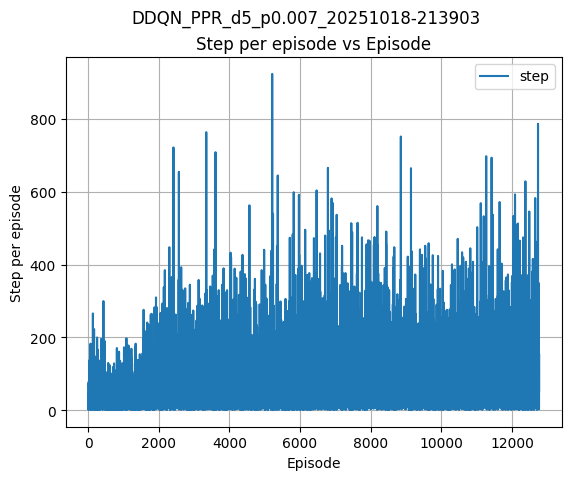

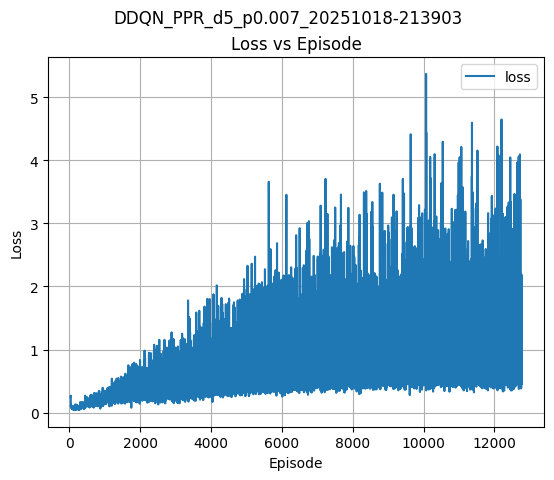

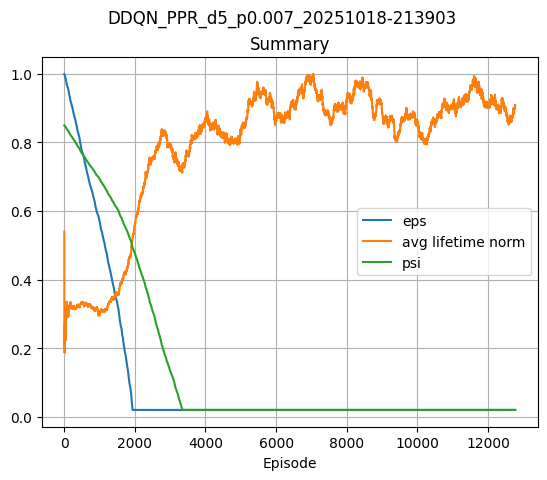

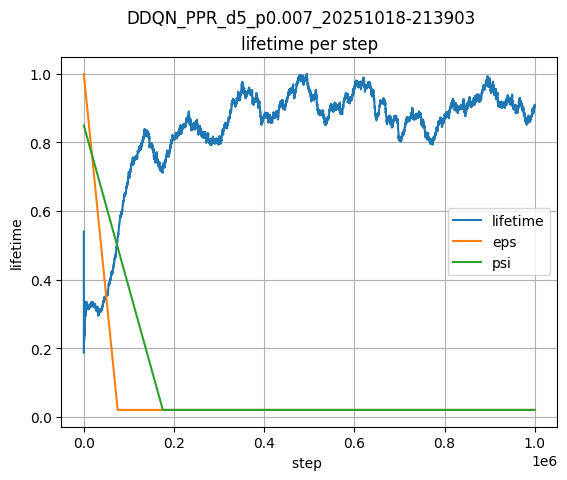

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# add
# k vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.scatter(episode, index_k, s=3, label='index policy k')
ax.set_title('reused policy')
ax.set_xlabel('episode')
ax.set_ylabel('')
ax.legend()
ax.grid()
plt.show()

# add 
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, np.cumsum(reward), label='cumulative reward')
ax.set_title('cumulative reward vs step')
ax.set_xlabel('steps')
ax.set_ylabel('reward')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
ax.plot(episode, psi, label='psi')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

# add
# avg lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime/np.max(avg_lifetime), label='lifetime')
ax.plot(step, eps, label = 'eps')
ax.plot(step, psi, label='psi')
ax.set_title('lifetime per step')
ax.set_xlabel('step ')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()



### test della policy ottenuta

In [ ]:
BEST_MODEL_PATH = r'runs\DDQN_PPR_d5_p0.007_20251018-213903\checkpoints\best_policy_net.pth'
policy_net.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
policy_net.eval() 

run = BEST_MODEL_PATH.split('\\')[1]

# test
N_episode = 6500
test_path = test_agent_performance(env, policy_net, policy, N_episode, device, log=True, run_name=run)



--- Inizio Test Deterministico (Episodi: 6500) ---
tested episode : 10, steps : 172, reward : 132.0, lifetime : 520
tested episode : 20, steps : 411, reward : 317.0, lifetime : 1155
tested episode : 30, steps : 60, reward : 50.0, lifetime : 180
tested episode : 40, steps : 8, reward : 7.0, lifetime : 25
tested episode : 50, steps : 240, reward : 196.0, lifetime : 750
tested episode : 60, steps : 40, reward : 28.0, lifetime : 110
tested episode : 70, steps : 110, reward : 88.0, lifetime : 365
tested episode : 80, steps : 5, reward : 4.0, lifetime : 15
tested episode : 90, steps : 462, reward : 377.0, lifetime : 1460
tested episode : 100, steps : 344, reward : 277.0, lifetime : 915
tested episode : 110, steps : 17, reward : 10.0, lifetime : 55
tested episode : 120, steps : 66, reward : 50.0, lifetime : 165
tested episode : 130, steps : 17, reward : 10.0, lifetime : 50
tested episode : 140, steps : 30, reward : 20.0, lifetime : 85
tested episode : 150, steps : 150, reward : 120.0, lifeti

In [12]:
test_path = r'test_runs\test_policy_DDQN_PPR_d5_p0.007_20251018-213903.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.mean(test_lifetimes)

Contenuto di test_runs\test_policy_DDQN_PPR_d5_p0.007_20251018-213903.json estratto con successo:


In [13]:
# nb: il paper originale calcola la vita media su un test greedy eseguito su un numero di episodi tale da garantire che
#     l'agente veda "almeno 1000000 di faulty syndrome" 
# la lifetime è calcolata come il  numero di singoli strati di ft syndrome creati in un qubit logico
# --> questo dato corrisponde alla somma di tutte le lifetime degli episodi di un test
print(np.sum(test_lifetimes))
#  6500 ep, 27 min
N_episode = 6500

2086635


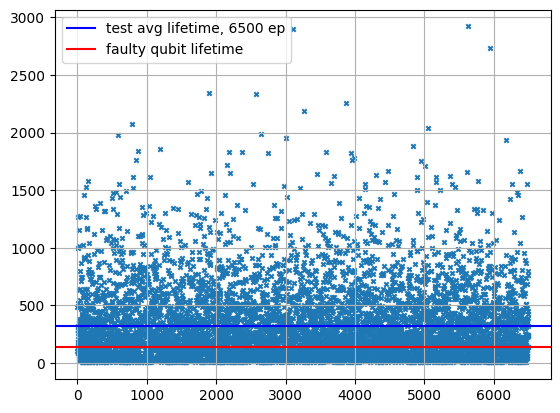

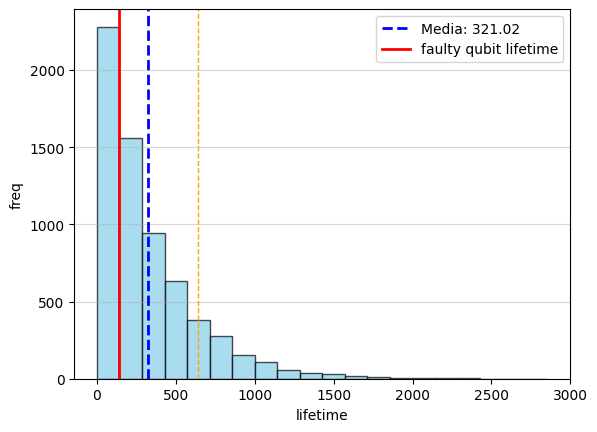

In [14]:
faulty_qubit_lifetime = 1/all_configs['p_phys']

fig, ax = plt.subplots()
ax.axhline(test_avg_lifetime, c='b', label=f'test avg lifetime, {N_episode} ep')
ax.scatter(range(N_episode), test_lifetimes, marker='x', s=10 )
ax.axhline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r')
ax.grid()
ax.legend()
plt.show()

bins = np.arange(0, np.max(test_lifetimes), faulty_qubit_lifetime)
# istogramma

plt.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.7, color='skyblue')
# Aggiungi linee di riferimento per la Media e la Deviazione Standard
plt.axvline(test_avg_lifetime, c='b', ls='dashed', linewidth=2, label=f'Media: {test_avg_lifetime:.2f}')
plt.axvline(test_avg_lifetime + test_std_lifetime, color='orange', linestyle='dashed', linewidth=1)
if test_avg_lifetime - test_std_lifetime > 0: plt.axvline(test_avg_lifetime - test_std_lifetime, color='orange', linestyle='dashed', linewidth=1, label=f'Media ± Std: {test_std_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r', lw=2)
# Etichette e Titolo
plt.xlabel('lifetime')
plt.ylabel('freq')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()



## p=0.009 [0.007, 0.005, 0.003, 0.001] 

In [15]:
# test env 0.009 con una libreria basata su [0.001, 0.003, 0.005, 0.007]

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "stopping_patience": 1000,        
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.009,            
                    "p_meas": 0.009,            
                    "success_threshold": 170,   # imposto circa la vita media ottenuta by scratch con p 0.009
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,  
                    "max_eps": 1.0,
                    "final_eps": 0.02,      
                    "exploration_fraction": 75000,
                    "max_psi": 0.85,             
                    "final_psi": 0.02,
                    "ppr_fraction": 175000,                       
                    "target_network_update_freq":5000, 
                    "gamma": 0.99}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali 
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# inizializzo l'Optimizer 
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# libreria di policy per PPR
model_paths = [r'runs\DDQN_d5_p0.001_20251013-230503\checkpoints\best_policy_net.pth',
               r'runs\DDQN_d5_p0.003_20251014-034106\checkpoints\best_policy_net.pth',
               r'runs\DDQN_d5_p0.005_20251014-081237\checkpoints\best_policy_net.pth',
               r'runs\DDQN_d5_p0.007_20251014-234730\checkpoints\best_policy_net.pth'
               ]
library = make_library(model_paths, policy_net, device)
print(f'Library creata con {len(library)} modelli.')

Library creata con 4 modelli.


In [ ]:
# train eseguito train_wit_ppr
timeS = time.time()
train_with_ppr(agent, env, policy, policy_net, memory, library, all_configs, device=device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento con PPR su 1000000 passi. Log in: runs\DDQN_PPR_d5_p0.009_20251019-025723

---------------------------------
Step : 3132/1000000
Episode : 100
Policy Index k : 4
Episode Step : 7 with 6 "reuse" actions
Episode Reward : 3.0
Avg Reward (Last 500 Ep) : 15.48
Best Avg Reward : -inf
Episode Lifetime : 30
Avg Lifetime (Last 500 Ep) : 72.90
Best Avg Lifetime : -inf
Success threshold : 170
Patience Counter : 0/1000
Metrics : Loss: 0.0701, Epsilon: 0.9591, Psi: 0.8351
Total Training Time : 31.58s
---------------------------------
                              

---------------------------------
Step : 5275/1000000
Episode : 200
Policy Index k : 3
Episode Step : 10 with 8 "reuse" actions
Episode Reward : 4.0
Avg Reward (Last 500 Ep) : 12.90
Best Avg Reward : -inf
Episode Lifetime : 20
Avg Lifetime (Last 500 Ep) : 62.40
Best Avg Lifetime : -inf
Success threshold : 170
Patience Counter : 0/1000
Metrics : Loss: 0.0890, Epsilon: 0.9311, Psi: 0.8250
Total Training Time : 63.46s
-

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

6 ore e 13 min


### valutazione training log

In [ ]:
# estrazione log di allenamento 
TRAINING_LOG_PATH =  r'runs\DDQN_PPR_d5_p0.009_20251019-025723\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con train_with_ppr : 
step = np.array([log_data['step'] for log_data in training_history])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reused_action = np.array([log_data['reuse_actions'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
psi = np.array([log_data['psi'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]

print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_PPR_d5_p0.009_20251019-025723\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 18474
numero step totali : 999948
best avg lifetime (rolling lenght 500) : 159.34
----------------------------------------------------------


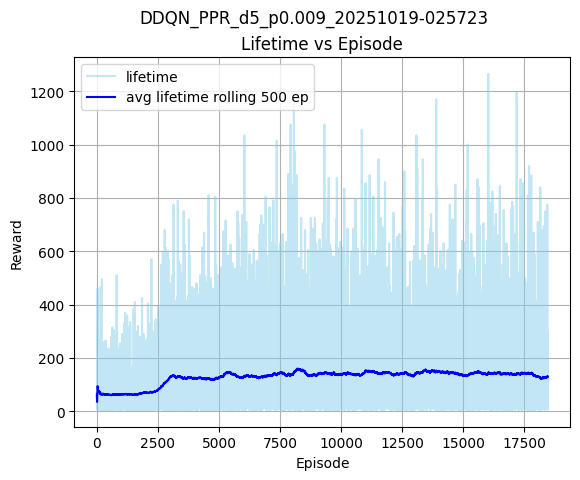

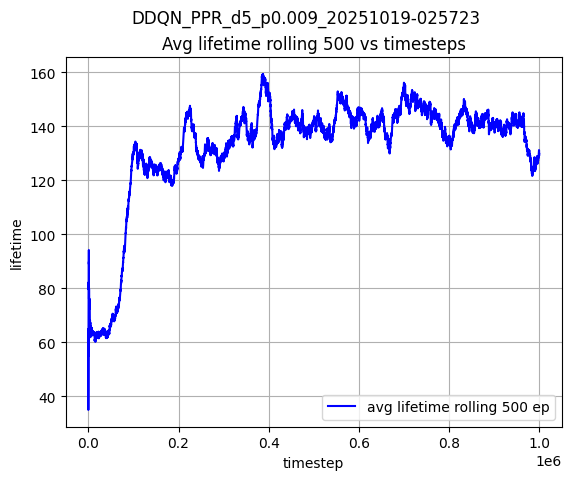

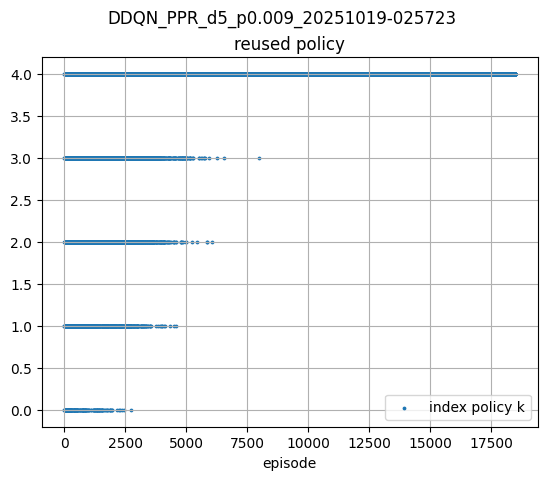

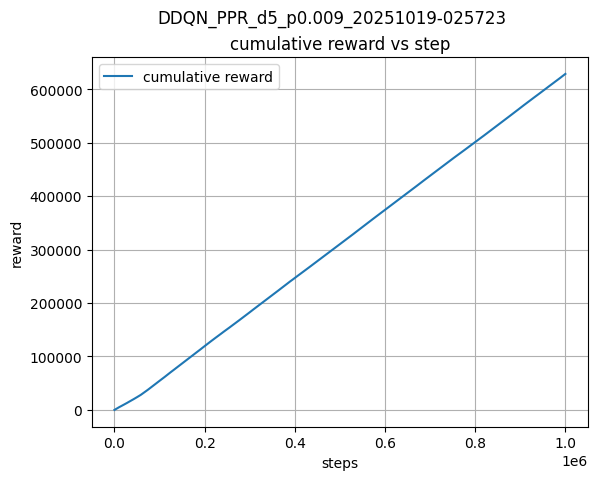

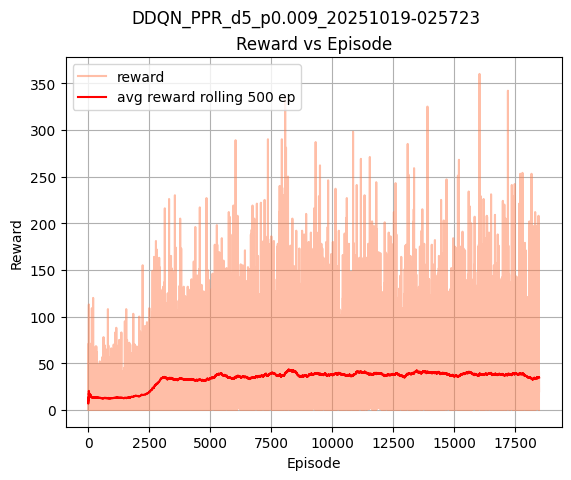

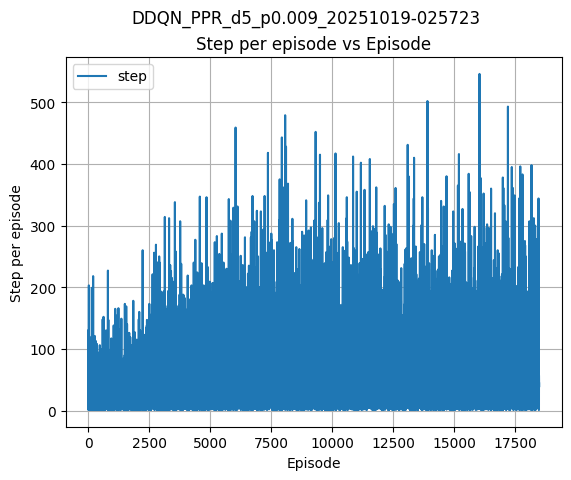

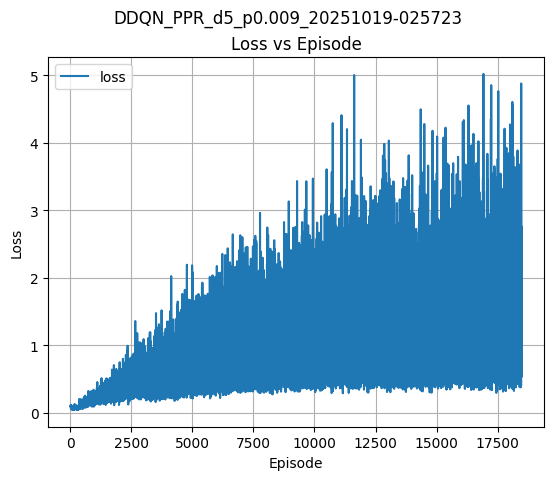

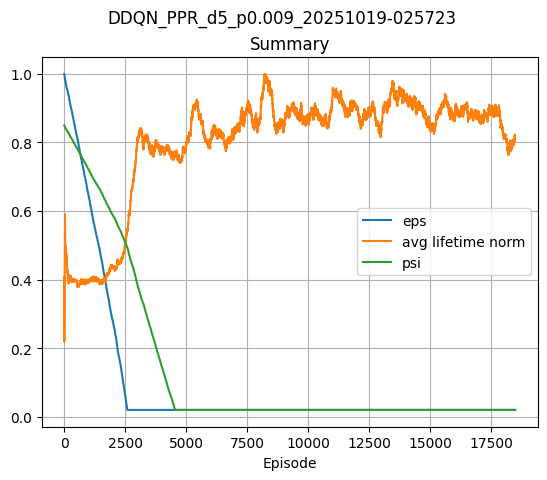

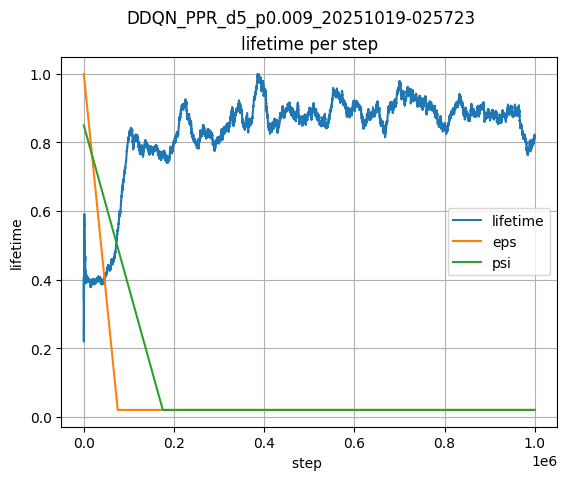

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# add
# k vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.scatter(episode, index_k, s=3, label='index policy k')
ax.set_title('reused policy')
ax.set_xlabel('episode')
ax.set_ylabel('')
ax.legend()
ax.grid()
plt.show()

# add 
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, np.cumsum(reward), label='cumulative reward')
ax.set_title('cumulative reward vs step')
ax.set_xlabel('steps')
ax.set_ylabel('reward')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
ax.plot(episode, psi, label='psi')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

# add
# avg lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime/np.max(avg_lifetime), label='lifetime')
ax.plot(step, eps, label = 'eps')
ax.plot(step, psi, label='psi')
ax.set_title('lifetime per step')
ax.set_xlabel('step ')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()



### test della policy ottenuta

In [ ]:
BEST_MODEL_PATH = r'runs\DDQN_PPR_d5_p0.009_20251019-025723\checkpoints\best_policy_net.pth'
policy_net.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
policy_net.eval() 

run = BEST_MODEL_PATH.split('\\')[1]

# test
N_episode = 15500
test_path = test_agent_performance(env, policy_net, policy, N_episode, device, log=True, run_name=run)



--- Inizio Test Deterministico (Episodi: 15500) ---
tested episode : 10, steps : 28, reward : 20.0, lifetime : 65
tested episode : 20, steps : 10, reward : 6.0, lifetime : 25
tested episode : 30, steps : 64, reward : 43.0, lifetime : 170
tested episode : 40, steps : 29, reward : 24.0, lifetime : 75
tested episode : 50, steps : 142, reward : 104.0, lifetime : 385
tested episode : 60, steps : 14, reward : 8.0, lifetime : 40
tested episode : 70, steps : 257, reward : 192.0, lifetime : 640
tested episode : 80, steps : 60, reward : 38.0, lifetime : 150
tested episode : 90, steps : 64, reward : 50.0, lifetime : 155
tested episode : 100, steps : 35, reward : 24.0, lifetime : 90
tested episode : 110, steps : 57, reward : 39.0, lifetime : 150
tested episode : 120, steps : 219, reward : 163.0, lifetime : 520
tested episode : 130, steps : 309, reward : 224.0, lifetime : 765
tested episode : 140, steps : 18, reward : 15.0, lifetime : 70
tested episode : 150, steps : 143, reward : 101.0, lifetime 

In [16]:
test_path = r'test_runs\test_policy_DDQN_PPR_d5_p0.009_20251019-025723.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.mean(test_lifetimes)

Contenuto di test_runs\test_policy_DDQN_PPR_d5_p0.009_20251019-025723.json estratto con successo:


In [17]:
# nb: il paper originale calcola la vita media su un test greedy eseguito su un numero di episodi tale da garantire che
#     l'agente veda "almeno 1000000 di faulty syndrome" 
# la lifetime è calcolata come il  numero di singoli strati di ft syndrome creati in un qubit logico
# --> questo dato corrisponde alla somma di tutte le lifetime degli episodi di un test
print(np.sum(test_lifetimes))
#  15500 ep, 70 min
N_episode = 15500

2705685


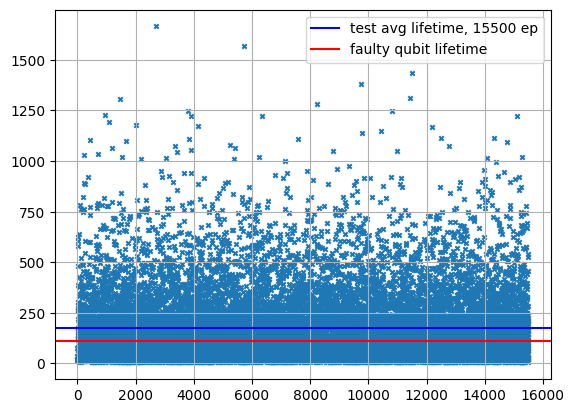

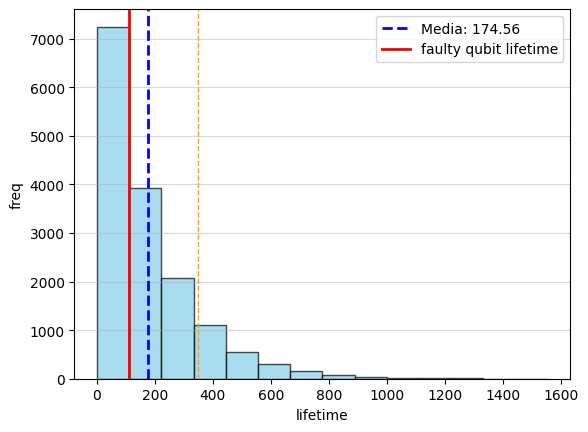

In [18]:
faulty_qubit_lifetime = 1/all_configs['p_phys']

fig, ax = plt.subplots()
ax.axhline(test_avg_lifetime, c='b', label=f'test avg lifetime, {N_episode} ep')
ax.scatter(range(N_episode), test_lifetimes, marker='x', s=10 )
ax.axhline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r')
ax.grid()
ax.legend()
plt.show()

bins = np.arange(0, np.max(test_lifetimes), faulty_qubit_lifetime)
# istogramma

plt.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.7, color='skyblue')
# Aggiungi linee di riferimento per la Media e la Deviazione Standard
plt.axvline(test_avg_lifetime, c='b', ls='dashed', linewidth=2, label=f'Media: {test_avg_lifetime:.2f}')
plt.axvline(test_avg_lifetime + test_std_lifetime, color='orange', linestyle='dashed', linewidth=1)
if test_avg_lifetime - test_std_lifetime > 0: plt.axvline(test_avg_lifetime - test_std_lifetime, color='orange', linestyle='dashed', linewidth=1, label=f'Media ± Std: {test_std_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r', lw=2)
# Etichette e Titolo
plt.xlabel('lifetime')
plt.ylabel('freq')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

